<a href="https://colab.research.google.com/github/ssinmani/Project_K-Means_ECG/blob/main/warmup_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import math


In [43]:
x_train = np.random.uniform (0,10,50)
y_train = 3 * x_train + 2 + np.random.normal (0,1,50)

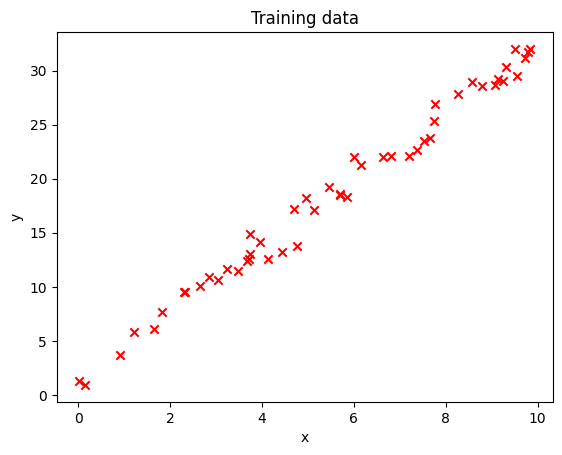

In [44]:
plt.scatter(x_train ,y_train, marker='x', c='r')
plt.title ("Training data");
plt.xlabel("x");
plt.ylabel("y");


In [45]:
def compute_cost (x ,y ,w ,b ):
  m = x.shape[0]
  cost_sum = 0
  for i in range(m):
          f_wb = w * x[i] + b
          cost = (f_wb - y[i]) ** 2
          cost_sum = cost_sum + cost
  total_cost = (1 / (2 * m)) * cost_sum

  return total_cost

In [46]:
print(compute_cost(x_train, y_train, 3, 2))
print(compute_cost(x_train, y_train, 0, 0))

0.5260456173575838
208.22534958974416


In [47]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_db += dj_db_i
        dj_dw += dj_dw_i
    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [48]:
dw, db = compute_gradient(x_train, y_train, 0, 0)
print(dw, db)

-126.60255166359718 -18.472926557453956


In [49]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    J_history = []
    p_history = []
    b = b_in
    w = w_in

    for i in range(num_iters):
        # Calculate the gradient and update the parameters using gradient_function
        dj_dw, dj_db = gradient_function(x, y, w , b)

        # Update Parameters using equation (3) above
        b = b - alpha * dj_db
        w = w - alpha * dj_dw

        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])
        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")

    return w, b, J_history, p_history #return w and J,w history for graphing

In [50]:
w, b, J_history, p_history = gradient_descent(
    x_train, y_train, 0, 0, 0.01, 1000, compute_cost, compute_gradient)
print(f"Final: w = {w:.3f}, b = {b:.3f}")

Iteration    0: Cost 7.68e+01  dj_dw: -1.266e+02, dj_db: -1.847e+01   w:  1.266e+00, b: 1.84729e-01
Iteration  100: Cost 5.75e-01  dj_dw:  2.487e-02, dj_db: -1.725e-01   w:  3.184e+00, b: 6.56200e-01
Iteration  200: Cost 5.50e-01  dj_dw:  2.034e-02, dj_db: -1.411e-01   w:  3.162e+00, b: 8.12289e-01
Iteration  300: Cost 5.34e-01  dj_dw:  1.664e-02, dj_db: -1.154e-01   w:  3.143e+00, b: 9.39941e-01
Iteration  400: Cost 5.23e-01  dj_dw:  1.361e-02, dj_db: -9.435e-02   w:  3.128e+00, b: 1.04434e+00
Iteration  500: Cost 5.15e-01  dj_dw:  1.113e-02, dj_db: -7.716e-02   w:  3.116e+00, b: 1.12972e+00
Iteration  600: Cost 5.10e-01  dj_dw:  9.100e-03, dj_db: -6.310e-02   w:  3.106e+00, b: 1.19954e+00
Iteration  700: Cost 5.07e-01  dj_dw:  7.442e-03, dj_db: -5.161e-02   w:  3.098e+00, b: 1.25664e+00
Iteration  800: Cost 5.05e-01  dj_dw:  6.086e-03, dj_db: -4.220e-02   w:  3.091e+00, b: 1.30334e+00
Iteration  900: Cost 5.03e-01  dj_dw:  4.978e-03, dj_db: -3.452e-02   w:  3.085e+00, b: 1.34154e+00


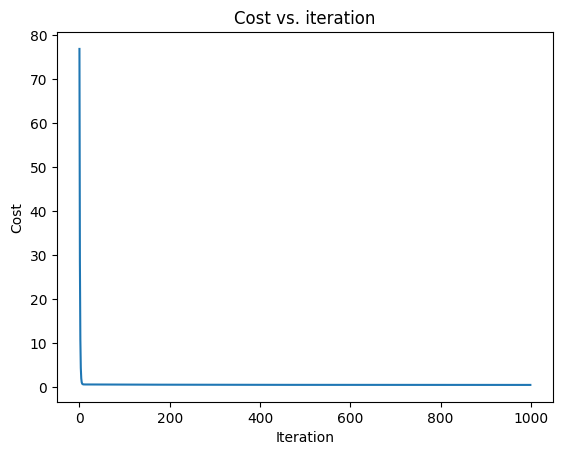

In [51]:
plt.plot(J_history)
plt.title("Cost vs. iteration")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()

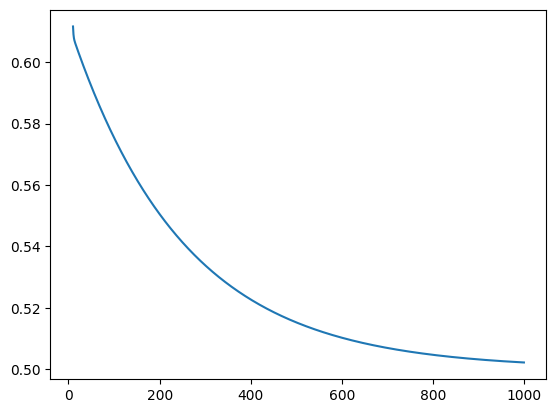

In [52]:
plt.plot(range(10, 1000), J_history[10:])
plt.show()

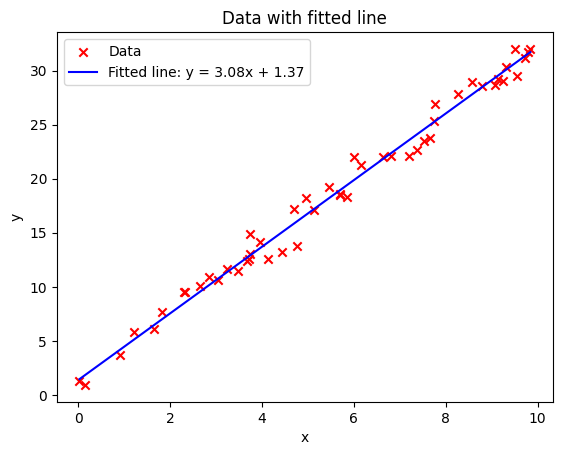

In [53]:
x_line = np.sort(x_train)
plt.scatter(x_train, y_train, marker="x", c="r", label="Data")
plt.plot(x_line, w * x_line + b, c="b", label=f"Fitted line: y = {w:.2f}x + {b:.2f}")
plt.title("Data with fitted line")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [54]:
x_new = 4.0
y_pred = w * x_new + b
print(f"Prediction for x = {x_new}: {y_pred:.2f}")

Prediction for x = 4.0: 13.70


In [55]:
experiments = [
    ("alpha=0.01,   1000 steps", 0.01, 1000),
    ("alpha=0.01,   5000 steps", 0.01, 5000),
    ("alpha=0.0001, 1000 steps", 0.0001, 1000),
    ("alpha=0.1,    1000 steps", 0.1, 1000),
]
for name, a, n in experiments:
    print(f"\n--- {name} ---")
    w_e, b_e, J_e, _ = gradient_descent(x_train, y_train, 0, 0, a, n,
                                        compute_cost, compute_gradient)
    print(f"RESULT: w = {w_e:.3f}, b = {b_e:.3f}, final cost = {J_e[-1]:.3g}")


--- alpha=0.01,   1000 steps ---
Iteration    0: Cost 7.68e+01  dj_dw: -1.266e+02, dj_db: -1.847e+01   w:  1.266e+00, b: 1.84729e-01
Iteration  100: Cost 5.75e-01  dj_dw:  2.487e-02, dj_db: -1.725e-01   w:  3.184e+00, b: 6.56200e-01
Iteration  200: Cost 5.50e-01  dj_dw:  2.034e-02, dj_db: -1.411e-01   w:  3.162e+00, b: 8.12289e-01
Iteration  300: Cost 5.34e-01  dj_dw:  1.664e-02, dj_db: -1.154e-01   w:  3.143e+00, b: 9.39941e-01
Iteration  400: Cost 5.23e-01  dj_dw:  1.361e-02, dj_db: -9.435e-02   w:  3.128e+00, b: 1.04434e+00
Iteration  500: Cost 5.15e-01  dj_dw:  1.113e-02, dj_db: -7.716e-02   w:  3.116e+00, b: 1.12972e+00
Iteration  600: Cost 5.10e-01  dj_dw:  9.100e-03, dj_db: -6.310e-02   w:  3.106e+00, b: 1.19954e+00
Iteration  700: Cost 5.07e-01  dj_dw:  7.442e-03, dj_db: -5.161e-02   w:  3.098e+00, b: 1.25664e+00
Iteration  800: Cost 5.05e-01  dj_dw:  6.086e-03, dj_db: -4.220e-02   w:  3.091e+00, b: 1.30334e+00
Iteration  900: Cost 5.03e-01  dj_dw:  4.978e-03, dj_db: -3.452e-0

/tmp/ipykernel_1244/277659014.py:7: RuntimeWarning: overflow encountered in scalar add
  cost_sum = cost_sum + cost
/tmp/ipykernel_1244/277659014.py:6: RuntimeWarning: overflow encountered in scalar power
  cost = (f_wb - y[i]) ** 2
/tmp/ipykernel_1244/737659332.py:11: RuntimeWarning: overflow encountered in scalar add
  dj_dw += dj_dw_i
/tmp/ipykernel_1244/950527411.py:13: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - alpha * dj_dw
